# Lab 9. Plotting and Visualization

In [2]:
student_name = ""   # e.g. "Arman Omar"


## Rules

1. Go **top to bottom**. Write your code where you see `# YOUR CODE HERE` or `None`.
2. Do not edit the *given data* cells or the *check* cells.
3. Use the **object-oriented style**: call methods on the `fig` and `ax` objects (`ax.plot(...)`, `ax.set_title(...)`),
   not `plt.title(...)`. In Jupyter a figure is closed after its cell runs, so `plt.xxx` would hit a new empty figure.
4. Every task ends with a **check cell** that prints `PASS` or `FAIL`. It never stops the notebook. The check looks at the
   figure objects (title, labels, number of lines or bars, legend and so on), so it can only judge what is really on the figure.
5. The last cell shows your automatic score.
6. Before you submit: **Kernel > Restart & Run All**, make sure nothing raises an error, save, upload the `.ipynb`.
7. **Defense:** at the end there are questions you will answer aloud. Be ready to change your plot live.

## Setup
Run this cell first. It imports the libraries and defines the self-check helper.

In [3]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.text import Annotation

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 120)
try:
    import seaborn as sns
    sns.set_theme(style="whitegrid")
    SEABORN = sns.__version__
except ImportError:
    SEABORN = None
    print("seaborn is NOT installed: run  pip install seaborn  and restart the kernel (needed for Part 4).")
print("pandas", pd.__version__, "| numpy", np.__version__, "| matplotlib", matplotlib.__version__, "| seaborn", SEABORN)

# ----- Self-check helper. Do not edit this cell. -----
POINTS = {"1.1": 4, "1.2": 5, "1.3": 5, "1.4": 4, "1.5": 4, "2.1": 5, "2.2": 5, "2.3": 5, "2.4": 5, "3.1": 3, "3.2": 4, "3.3": 3, "3.4": 5, "3.5": 5, "3.6": 4, "4.1": 4, "4.2": 4, "4.3": 3, "4.4": 4, "5.1": 3, "5.2": 4, "5.3": 3, "5.4": 3, "5.5": 3, "5.6": 3}
_results = {}


def check(task_id, condition):
    """Run `condition` (a lambda returning True/False), print PASS or FAIL and remember the result."""
    try:
        ok = bool(condition())
        print(f"Task {task_id}: {'PASS' if ok else 'FAIL'}")
    except Exception as exc:
        ok = False
        print(f"Task {task_id}: FAIL ({type(exc).__name__}: {exc})")
    _results[task_id] = ok


def summary():
    """Print the automatic score per task and per part."""
    rows, by_part, part_max = [], {}, {}
    for tid, pts in POINTS.items():
        got = pts if _results.get(tid) else 0
        part = tid.split(".")[0]
        by_part[part] = by_part.get(part, 0) + got
        part_max[part] = part_max.get(part, 0) + pts
        rows.append((tid, pts, got, "PASS" if _results.get(tid) else ("FAIL" if tid in _results else "not run")))
    display(pd.DataFrame(rows, columns=["task", "max", "earned", "result"]).set_index("task"))
    print()
    for part in sorted(part_max, key=int):
        print(f"Part {part}: {by_part[part]:>3} / {part_max[part]}")
    print(f"TOTAL (automatic): {sum(by_part.values())} / {sum(part_max.values())}")

pandas 2.3.3 | numpy 2.3.5 | matplotlib 3.10.8 | seaborn 0.13.2


## Given data

| Name | What it is |
|---|---|
| `tips` | 120 restaurant bills: `total_bill`, `tip`, `smoker`, `day`, `time`, `size`, `tip_pct` |
| `monthly` | revenue of three regions by month (million KZT) |
| `kz` | 21 regions and cities of Kazakhstan: `region`, `kind` (`region` or `city`), `area_km2`, `pop_2009`, `pop_2022` (used in Part 5) |
| `walk`, `noise`, `xs`, `ys` | small arrays for Part 1 |

The data is generated with a fixed seed, so everybody has the same numbers.
**Trap:** one row of `tips` has a data entry error (a 240 percent tip). You will meet it in Part 3.

In [4]:
rng = np.random.default_rng(42)

# ---- restaurant bills (like the tips dataset of the lecture) ----
n = 120
day = rng.choice(["Thur", "Fri", "Sat", "Sun"], size=n, p=[0.2, 0.1, 0.35, 0.35])
time = np.where(np.isin(day, ["Sat", "Sun"]), "Dinner", rng.choice(["Lunch", "Dinner"], size=n, p=[0.7, 0.3]))
total_bill = np.round(rng.lognormal(mean=2.9, sigma=0.4, size=n), 2)
tip_pct = np.clip(rng.normal(0.16, 0.04, size=n), 0.05, None)
tips = pd.DataFrame({
    "total_bill": total_bill,
    "tip": np.round(total_bill * tip_pct, 2),
    "smoker": rng.choice(["No", "Yes"], size=n, p=[0.6, 0.4]),
    "day": day,
    "time": time,
    "size": rng.integers(1, 7, size=n),
})
tips.loc[7, "tip"] = round(tips.loc[7, "total_bill"] * 2.4, 2)     # a data entry error: a 240 percent tip
tips["tip_pct"] = tips["tip"] / tips["total_bill"]

# ---- monthly revenue by region, million KZT ----
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
monthly = pd.DataFrame(
    np.round(50 + rng.normal(2, 4, size=(12, 3)).cumsum(axis=0), 1),
    columns=["North", "South", "East"], index=months,
)

# ---- small arrays for Part 1 ----
walk = rng.standard_normal(30).cumsum()          # a random walk
noise = rng.normal(15, 5, size=100)              # values mostly between 0 and 30
xs = np.arange(30)
ys = xs + 3 * rng.standard_normal(30)

# ---- regions of Kazakhstan (Wikipedia table: area km2, population 2009 and 2022) ----
kz = pd.DataFrame(
    [("Abai", "region", 185500, 654423, 610183), ("Aqmola", "region", 146219, 737495, 786012),
     ("Aqtobe", "region", 300629, 757768, 924845), ("Almaty", "city", 682, 1449696, 2147113),
     ("Almaty Region", "region", 105100, 1103237, 1497025), ("Astana", "city", 797, 613006, 1340782),
     ("Atyrau", "region", 118631, 510377, 689674), ("Baikonur", "city", 57, 36175, 34544),
     ("East Kazakhstan", "region", 97700, 742170, 730818), ("Jambyl", "region", 144264, 1022129, 1215482),
     ("Jetisu", "region", 118500, 620593, 698952), ("Karaganda", "region", 239100, 1118036, 1134146),
     ("Kostanay", "region", 196001, 885570, 832445), ("Kyzylorda", "region", 226019, 678794, 830901),
     ("Mangystau", "region", 165642, 485392, 761401), ("North Kazakhstan", "region", 97993, 596535, 534966),
     ("Pavlodar", "region", 124800, 742475, 754829), ("Shymkent", "city", 1163, 730873, 1184113),
     ("Turkistan", "region", 116100, 1738484, 2110502), ("West Kazakhstan", "region", 151339, 598880, 686655),
     ("Ulytau", "region", 188900, 223664, 221014)],
    columns=["region", "kind", "area_km2", "pop_2009", "pop_2022"],
)

print(tips.shape, monthly.shape, kz.shape)
tips.head()

(120, 7) (12, 3) (21, 5)


,total_bill,tip,smoker,day,time,size,tip_pct
0,13.58,2.75,No,Sun,Dinner,1,0.202504
1,13.99,2.37,Yes,Sat,Dinner,6,0.169407
2,7.70,1.30,No,Sun,Dinner,1,0.168831
3,17.03,2.91,No,Sun,Dinner,2,0.170875
4,11.88,1.49,Yes,Thur,Lunch,5,0.125421


---
# Part 1. Figures, subplots, line styles, legends (22 points)

| Goal | Code |
|---|---|
| figure with a grid of axes | `fig, axes = plt.subplots(2, 2, sharex=True, figsize=(8, 6))` |
| draw on one axes | `axes[0, 0].plot(...)`, `.hist(...)`, `.scatter(...)` |
| format string | `"ko--"` = black (`k`), circle markers (`o`), dashed line (`--`) |
| legend | give `label="..."` to every line, then `ax.legend(loc="best")` |
| spacing | `fig.subplots_adjust(wspace=..., hspace=...)` |

In this part you fill **one figure with four panels** step by step.

### Theory: Figure, Axes and the two styles

* A **Figure** is the whole canvas. An **Axes** is one plot area inside it (with its own x axis, y axis, title, legend).
* **pyplot style:** `plt.plot(...)`, `plt.title(...)` act on the "current" axes (hidden global state). Quick, but in Jupyter the figure
  is closed after the cell runs, so a later `plt.title(...)` hits a **new empty figure**.
* **Object-oriented style (use this in the lab):** `fig, ax = plt.subplots()` and then `ax.plot(...)`, `ax.set_title(...)`.
  With several panels `plt.subplots(2, 2)` returns `axes` as a 2D array: `axes[0, 1]` is row 0, column 1.
* A **format string** `"g--o"` = colour `g` (green) + line style `--` (dashed) + marker `o` (circles).
  Colours: `b g r c m y k w`. Markers: `o * s ^ . +`. Styles: `-  --  :  -.`.
* `hist(data, bins=...)` counts values in bins, `scatter(x, y)` draws points, `legend()` shows the `label=` of every line.

### Example (run it and change something)

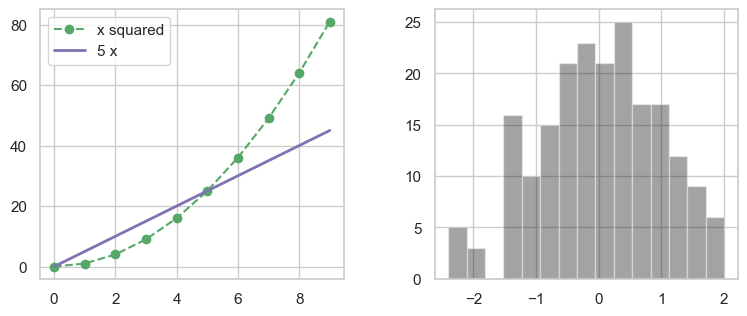

In [5]:
ex_x = np.arange(10)
ex_fig, ex_axes = plt.subplots(1, 2, figsize=(9, 3.5))            # 1 row, 2 columns -> axes is a 1D array
ex_axes[0].plot(ex_x, ex_x ** 2, "g--o", label="x squared")         # format string
ex_axes[0].plot(ex_x, 5 * ex_x, "m-", linewidth=2, label="5 x")     # keyword arguments
ex_axes[0].legend(loc="upper left")
ex_axes[1].hist(np.random.default_rng(0).normal(size=200), bins=15, color="k", alpha=0.4)
ex_fig.subplots_adjust(wspace=0.3)                                  # gap between the panels

### Task 1.1 (4 pts): Create the figure

Create `fig` and `axes`: a figure with **2 rows and 2 columns** of axes, size **8 by 6 inches**,
where **all axes share the same x axis** (`sharex=True`).

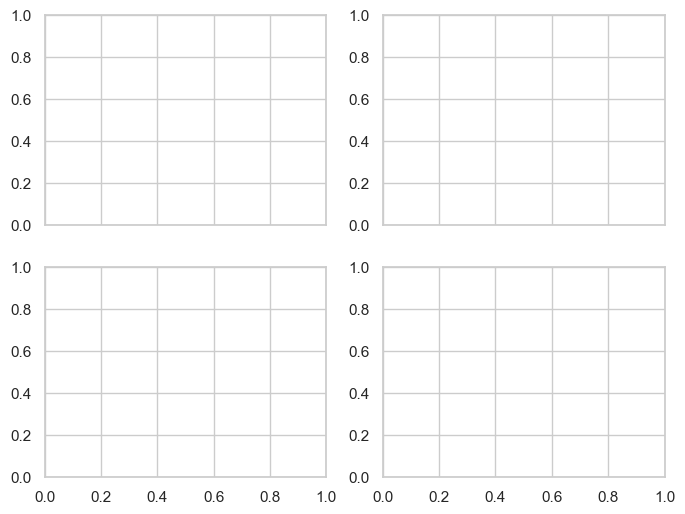

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(8, 6), sharex=True)

In [7]:
check("1.1", lambda: len(fig.axes) == 4 and axes.shape == (2, 2) and tuple(fig.get_size_inches()) == (8.0, 6.0)
      and axes[0, 0].get_shared_x_axes().joined(axes[0, 0], axes[1, 1])
      and axes[0, 0].get_shared_x_axes().joined(axes[0, 0], axes[1, 0]))

Task 1.1: PASS


### Task 1.2 (5 pts): Format string

On the **top left** axes `axes[0, 0]` plot `walk` with the format string `"ko--"`.

In [8]:
axes[0, 0].plot(walk, "ko--")

Task 1.2: PASS


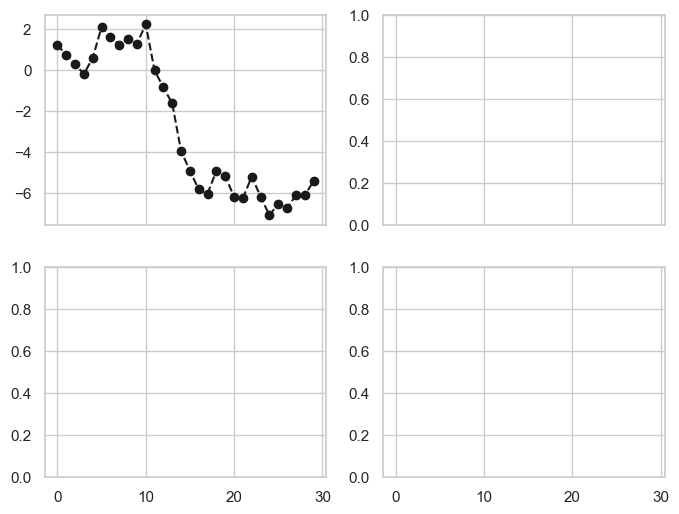

In [9]:
def _t12():
    lines = axes[0, 0].lines
    return (len(lines) == 1 and lines[0].get_color() == "k" and lines[0].get_marker() == "o"
            and lines[0].get_linestyle() == "--" and np.allclose(lines[0].get_ydata(), walk))
check("1.2", _t12)
fig

### Task 1.3 (5 pts): drawstyle and legend

On the **top right** axes `axes[0, 1]` draw `walk` twice:

1. black dashed line `"k--"` with `label="Default"`
2. black solid line `"k-"` with `drawstyle="steps-post"` and `label="steps-post"`

Then add a legend with `loc="best"`.

In [10]:
axes[0, 1].plot(walk, "k--", label="Default")
axes[0, 1].plot(walk, "k-", drawstyle="steps-post", label="steps-post")
axes[0, 1].legend(loc="best")

Task 1.3: PASS


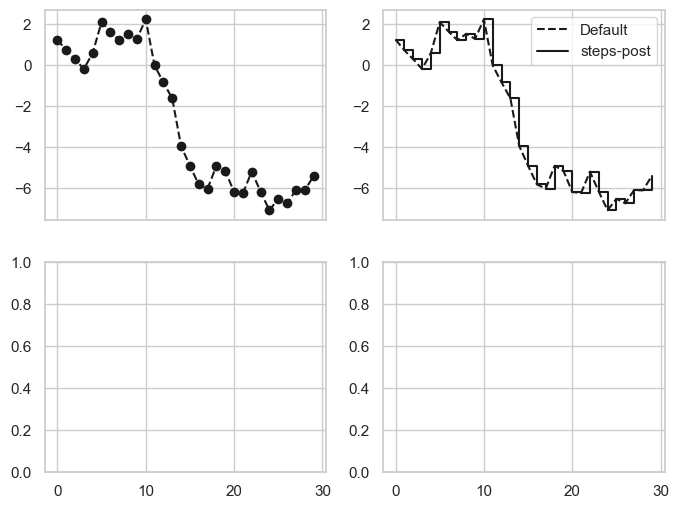

In [11]:
def _t13():
    ax = axes[0, 1]
    lines = ax.lines
    leg = ax.get_legend()
    return (len(lines) == 2 and lines[1].get_drawstyle() == "steps-post" and leg is not None
            and [t.get_text() for t in leg.get_texts()] == ["Default", "steps-post"])
check("1.3", _t13)
fig

### Task 1.4 (4 pts): Histogram

On the **bottom right** axes `axes[1, 1]` draw a histogram of `noise` with `bins=20`, `color="k"` and `alpha=0.3`.

In [12]:
axes[1, 1].hist(noise, bins=20, color="k", alpha=0.3)

(array([ 2.,  1.,  2.,  3.,  5.,  9.,  4.,  3.,  2.,  9., 13.,  7.,  9.,
         6.,  6.,  7.,  5.,  1.,  5.,  1.]),
 array([ 3.59631077,  4.67868415,  5.76105752,  6.8434309 ,  7.92580427,
         9.00817764, 10.09055102, 11.17292439, 12.25529777, 13.33767114,
        14.42004451, 15.50241789, 16.58479126, 17.66716464, 18.74953801,
        19.83191138, 20.91428476, 21.99665813, 23.07903151, 24.16140488,
        25.24377825]),
 <BarContainer object of 20 artists>)

Task 1.4: PASS


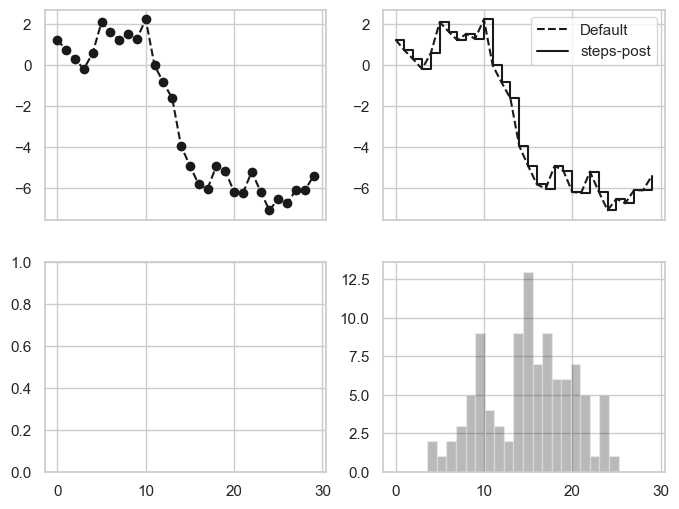

In [13]:
check("1.4", lambda: len(axes[1, 1].patches) == 20 and axes[1, 1].patches[0].get_alpha() == 0.3
      and sum(p.get_height() for p in axes[1, 1].patches) == len(noise))
fig

### Task 1.5 (4 pts): Scatter and spacing

1. On the **bottom left** axes `axes[1, 0]` draw a scatter plot of `xs` against `ys`.
2. Adjust the spacing of the whole figure: `wspace=0.3` and `hspace=0.4` (use the **figure** method `fig.subplots_adjust`).

In [14]:
axes[1, 0].scatter(xs, ys)
fig.subplots_adjust(wspace=0.3, hspace=0.4)

Task 1.5: PASS


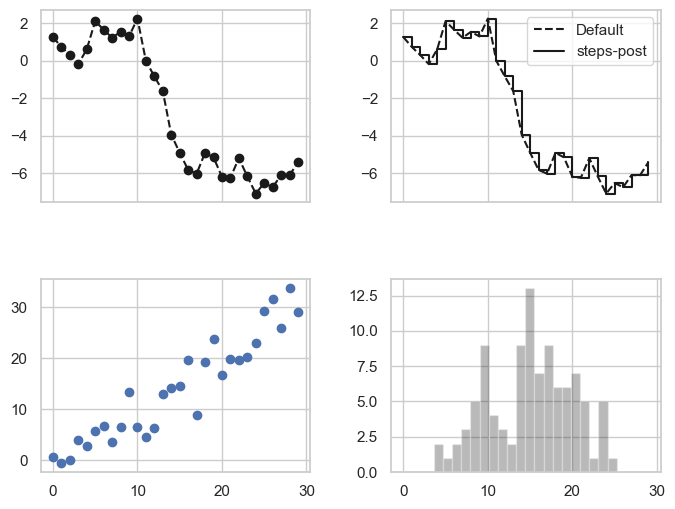

In [15]:
check("1.5", lambda: len(axes[1, 0].collections) == 1 and len(axes[1, 0].collections[0].get_offsets()) == 30
      and fig.subplotpars.wspace == 0.3 and fig.subplotpars.hspace == 0.4)
fig

---
# Part 2. Titles, labels, ticks, annotations, saving (20 points)

| Goal | Code |
|---|---|
| title and axis names | `ax.set_title("...")`, `ax.set_xlabel("...")`, `ax.set_ylabel("...")` or `ax.set(title=..., xlabel=..., ylabel=...)` |
| tick positions, then labels | `ax.set_xticks([...])`, `ax.set_xticklabels([...], rotation=45)` |
| annotation with an arrow | `ax.annotate("text", xy=(x, y), xytext=(x2, y2), arrowprops=dict(facecolor="black", shrink=0.05))` |
| save | `fig.savefig("name.png", dpi=200, bbox_inches="tight")` |

The next cell draws the North revenue. The x positions are `0..11` and the months are `months`.

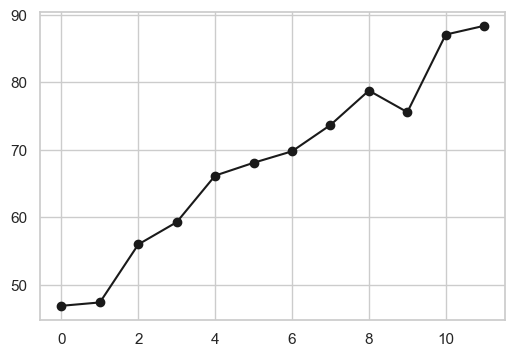

In [16]:
fig_n, ax_n = plt.subplots(figsize=(6, 4))
ax_n.plot(range(12), monthly["North"], "k-o", label="North")

### Theory: making a plot readable

| What | Method | Note |
|---|---|---|
| title, axis names | `ax.set_title("t")`, `ax.set_xlabel("x")`, `ax.set_ylabel("y")` | or all at once: `ax.set(title="t", xlabel="x", ylabel="y")` |
| tick positions | `ax.set_xticks([0, 1, 2])` | numbers where the ticks are |
| tick texts | `ax.set_xticklabels(["a", "b", "c"], rotation=45)` | **after** `set_xticks`, same number of items |
| annotation | `ax.annotate("text", xy=(x, y), xytext=(x2, y2), arrowprops=dict(facecolor="black", shrink=0.05))` | `xy` = point, `xytext` = where the text sits |
| save | `fig.savefig("name.png", dpi=200, bbox_inches="tight")` | format comes from the extension; `dpi` * inches = pixels |

### Example (run it and change something)

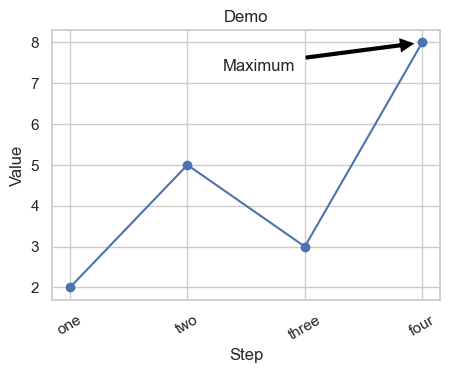

In [17]:
ex_fig, ex_ax = plt.subplots(figsize=(5, 3.5))
ex_ax.plot([2, 5, 3, 8], "b-o")
ex_ax.set(title="Demo", xlabel="Step", ylabel="Value")
ex_ax.set_xticks([0, 1, 2, 3])
ex_ax.set_xticklabels(["one", "two", "three", "four"], rotation=30)
ex_ax.annotate("Maximum", xy=(3, 8), xytext=(1.3, 7.3), arrowprops=dict(facecolor="black", shrink=0.05))
ex_fig.savefig("demo_example.png", dpi=100, bbox_inches="tight")   # 5 inches * 100 dpi = about 500 pixels

### Task 2.1 (5 pts): Title, axis names, legend

On `ax_n` set:

* title `"North region revenue"`
* x label `"Month"`
* y label `"Revenue, million KZT"`

and show the legend.

In [18]:
ax_n.set(title="North region revenue", xlabel="Month", ylabel="Revenue, million KZT")
ax_n.legend()

Task 2.1: PASS


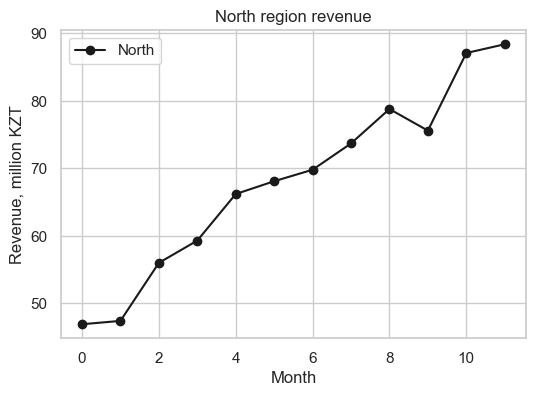

In [19]:
check("2.1", lambda: ax_n.get_title() == "North region revenue" and ax_n.get_xlabel() == "Month"
      and ax_n.get_ylabel() == "Revenue, million KZT" and ax_n.get_legend() is not None)
fig_n

### Task 2.2 (5 pts): Ticks and tick labels

Put a tick at every position `0..11` and write the month names (`months`) there, rotated by **45 degrees**.
Remember: first `set_xticks`, then `set_xticklabels`.

In [20]:
ax_n.set_xticks(range(12))
ax_n.set_xticklabels(months, rotation=45)

[Text(0, 0, 'Jan'),
 Text(1, 0, 'Feb'),
 Text(2, 0, 'Mar'),
 Text(3, 0, 'Apr'),
 Text(4, 0, 'May'),
 Text(5, 0, 'Jun'),
 Text(6, 0, 'Jul'),
 Text(7, 0, 'Aug'),
 Text(8, 0, 'Sep'),
 Text(9, 0, 'Oct'),
 Text(10, 0, 'Nov'),
 Text(11, 0, 'Dec')]

Task 2.2: PASS


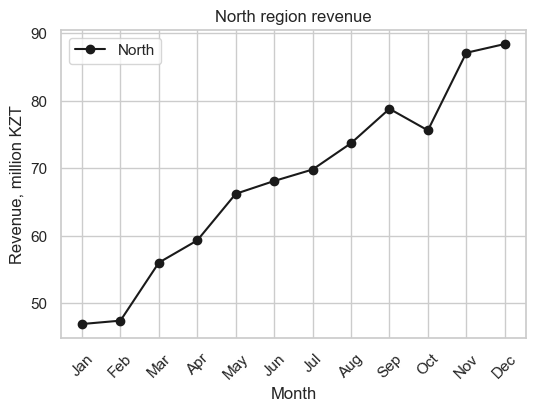

In [21]:
check("2.2", lambda: list(ax_n.get_xticks()) == list(range(12))
      and [t.get_text() for t in ax_n.get_xticklabels()] == months
      and ax_n.get_xticklabels()[0].get_rotation() == 45)
fig_n

### Task 2.3 (5 pts): Annotate the peak

1. `peak_idx`: the **position** (0 to 11) of the month with the highest North revenue
2. `peak_val`: that highest revenue
3. Add an annotation with the text `"Peak"` that points (`xy`) at the peak. Move the text away with `xytext` and draw an arrow
   with `arrowprops`.

*Hint:* `monthly["North"].argmax()` or `.to_numpy().argmax()`; `.max()`.

In [22]:
peak_idx = int(monthly["North"].to_numpy().argmax())
peak_val = monthly["North"].max()
ax_n.annotate("Peak", xy=(peak_idx, peak_val), xytext=(15, 25), textcoords="offset points", arrowprops=dict(arrowstyle="->"))

Text(15, 25, 'Peak')

Task 2.3: PASS


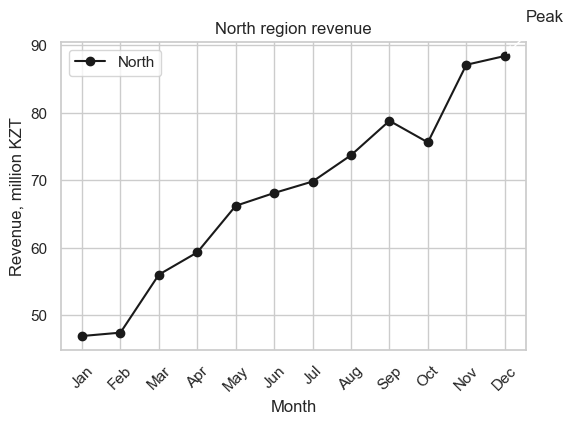

In [23]:
def _t23():
    anns = [t for t in ax_n.texts if isinstance(t, Annotation)]
    return (peak_idx == int(monthly["North"].to_numpy().argmax()) and peak_val == monthly["North"].max()
            and len(anns) == 1 and anns[0].get_text() == "Peak" and np.allclose(anns[0].xy, (peak_idx, peak_val))
            and anns[0].arrow_patch is not None)
check("2.3", _t23)
fig_n

### Task 2.4 (5 pts): Save the figure

Save `fig_n` to the file `north_revenue.png` with **dpi=200** and `bbox_inches="tight"`.

In [24]:
fig_n.savefig("north_revenue.png", dpi=200, bbox_inches="tight")

In [25]:
def _png_width(path):
    with open(path, "rb") as f:
        head = f.read(24)
    return head[:8] == b"\x89PNG\r\n\x1a\n", int.from_bytes(head[16:20], "big")

check("2.4", lambda: os.path.exists("north_revenue.png") and _png_width("north_revenue.png")[0]
      and _png_width("north_revenue.png")[1] > 1000)   # 6 inches * 200 dpi is about 1200 pixels

Task 2.4: PASS


---
# Part 3. Plotting with pandas (24 points)

`Series.plot` and `DataFrame.plot` call matplotlib for you. The index becomes the x axis.

| Goal | Code |
|---|---|
| line plot, one line per column | `df.plot()` |
| one panel per column | `df.plot(subplots=True, sharex=True)` |
| bars: grouped, horizontal, stacked | `df.plot.bar()`, `df.plot.barh(stacked=True)` |
| histogram, density | `s.plot.hist(bins=30)`, `s.plot.density()` |
| draw on an existing axes | `s.plot.hist(ax=ax)` |

### Theory: pandas calls matplotlib for you

* `df.plot()` draws **one line per column**, the **index is the x axis**, the legend is created automatically.
* Other kinds: `df.plot.bar()` (grouped bars, one group per row), `df.plot.barh(stacked=True)` (stacked, horizontal),
  `s.plot.hist(bins=30)`, `s.plot.density()` (smoothed histogram, needs `scipy`), `s.plot.pie()`.
* `subplots=True` gives one panel per column. `ax=some_axes` draws into an axes you made yourself (that is how panels are combined).
* Every pandas plot **returns the Axes**, so you can keep customising it: `ax = df.plot(); ax.set_title("...")`.
* **Shares instead of counts:** `ct = pd.crosstab(a, b)` counts pairs; `ct.div(ct.sum(axis=1), axis=0)` divides each row by its total,
  so each row sums to 1 and rows of different size can be compared.

### Example (run it and change something)

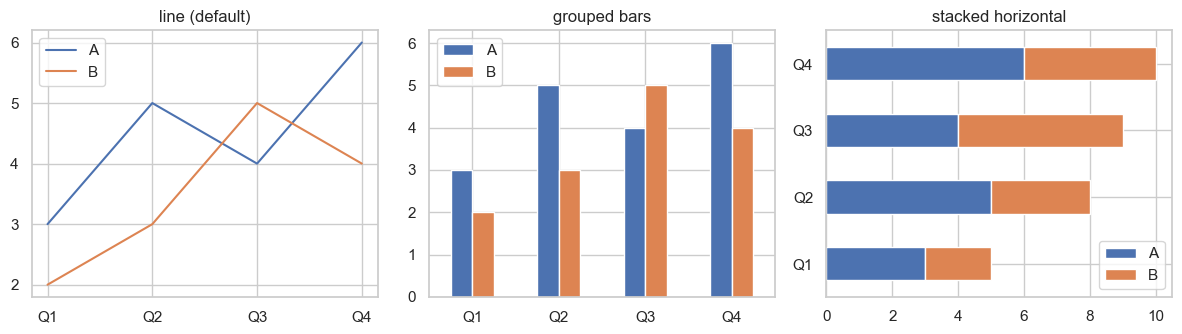

In [26]:
ex_df = pd.DataFrame({"A": [3, 5, 4, 6], "B": [2, 3, 5, 4]}, index=["Q1", "Q2", "Q3", "Q4"])
ex_fig, ex_axes = plt.subplots(1, 3, figsize=(12, 3.5))
ex_df.plot(ax=ex_axes[0], title="line (default)")                       # index on x, one line per column
ex_df.plot.bar(ax=ex_axes[1], rot=0, title="grouped bars")
ex_df.plot.barh(ax=ex_axes[2], stacked=True, title="stacked horizontal")
ex_fig.tight_layout()

### Task 3.1 (3 pts): Remove the outlier

Make `clean`: a copy of `tips` **without** rows where `tip_pct` is **1 or more** (a tip above 100 percent of the bill is an
entry error).

In [27]:
clean = tips.loc[tips["tip_pct"] < 1].copy()

In [28]:
check("3.1", lambda: len(clean) == len(tips) - 1 and clean["tip_pct"].max() < 1)

Task 3.1: PASS


### Task 3.2 (4 pts): DataFrame line plot

Plot all three columns of `monthly` as lines on one axes with `monthly.plot(...)`, `figsize=(8, 4)` and
`title="Revenue by region"`. Store the returned axes in `ax_line`.

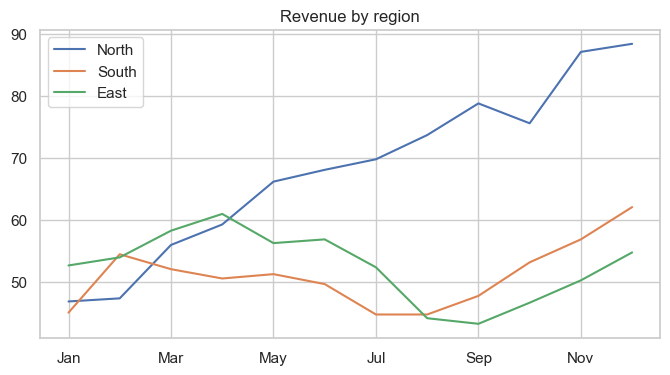

In [29]:
ax_line = monthly.plot(figsize=(8, 4), title="Revenue by region")

In [30]:
check("3.2", lambda: ax_line.get_title() == "Revenue by region" and len(ax_line.lines) == 3
      and [t.get_text() for t in ax_line.get_legend().get_texts()] == ["North", "South", "East"])

Task 3.2: PASS


### Task 3.3 (3 pts): One panel per column

Plot `monthly` again, but with **each column in its own panel** sharing the x axis, `figsize=(8, 6)`.
Store the returned array of axes in `axes_sub`.

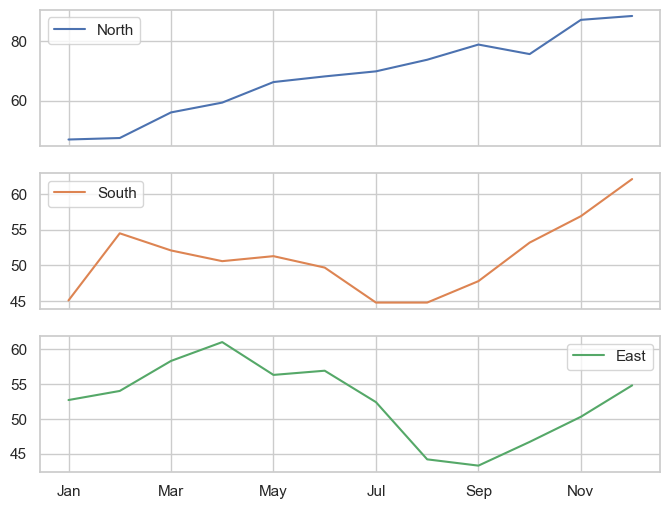

In [31]:
axes_sub = monthly.plot(subplots=True, sharex=True, figsize=(8, 6))

In [32]:
check("3.3", lambda: len(axes_sub) == 3 and all(len(a.lines) == 1 for a in axes_sub)
      and tuple(axes_sub[0].figure.get_size_inches()) == (8.0, 6.0))

Task 3.3: PASS


### Task 3.4 (5 pts): Grouped bar chart

Use `clean`:

1. `avg`: the **mean `tip_pct`** for every combination of `day` (rows) and `smoker` (columns). Use `groupby` and `unstack`.
2. `ax_bar`: a grouped bar chart of `avg` with horizontal tick labels (`rot=0`).

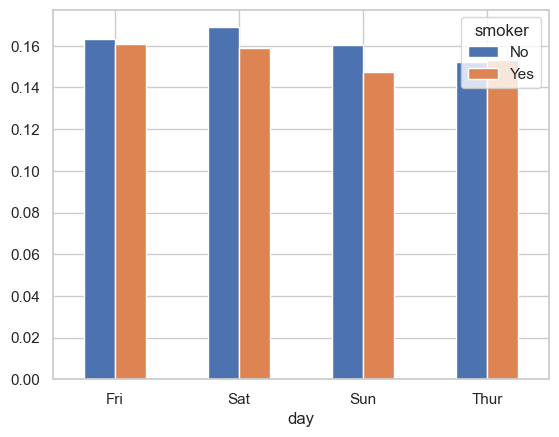

In [33]:
avg = clean.groupby(["day", "smoker"])["tip_pct"].mean().unstack()
ax_bar = avg.plot.bar(rot=0)

In [34]:
def _t34():
    expected = clean.pivot_table(index="day", columns="smoker", values="tip_pct", aggfunc="mean")
    heights = sorted(p.get_height() for p in ax_bar.patches)
    return (avg.shape == (4, 2) and np.allclose(avg.sort_index().to_numpy(), expected.sort_index().to_numpy())
            and len(ax_bar.patches) == avg.size and np.allclose(heights, sorted(avg.to_numpy().ravel()))
            and [t.get_text() for t in ax_bar.get_legend().get_texts()] == ["No", "Yes"])
check("3.4", _t34)

Task 3.4: PASS


### Task 3.5 (5 pts): Shares as stacked bars

How is the **party size** distributed on each day? Use `clean`:

1. `ct`: `pd.crosstab` of `day` (rows) and `size` (columns), counts.
2. `shares`: divide every row of `ct` by its row total, so that each **row sums to 1**
   (`ct.div(ct.sum(axis=1), axis=0)`).
3. `ax_share`: a **horizontal stacked** bar chart of `shares`.

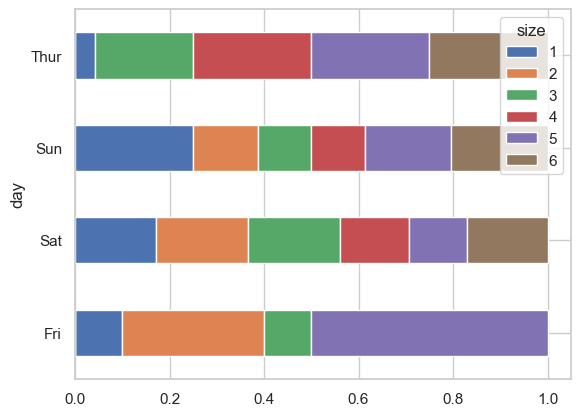

In [35]:
ct = pd.crosstab(clean["day"], clean["size"])
shares = ct.div(ct.sum(axis=1), axis=0)
ax_share = shares.plot.barh(stacked=True)

In [36]:
check("3.5", lambda: ct.to_numpy().sum() == len(clean) and np.allclose(shares.sum(axis=1), 1)
      and len(ax_share.patches) == shares.size and ax_share.get_xlim()[1] < 1.1)

Task 3.5: PASS


### Task 3.6 (4 pts): Histogram and density

Create `fig_h, axes_h = plt.subplots(1, 2, figsize=(10, 4))`. Then plot the `tip_pct` of **`clean`** with pandas:

* left axes: histogram with `bins=30`
* right axes: density plot

*Hint:* pass `ax=axes_h[0]` and `ax=axes_h[1]`. The density plot needs `scipy`.

<Axes: ylabel='Density'>

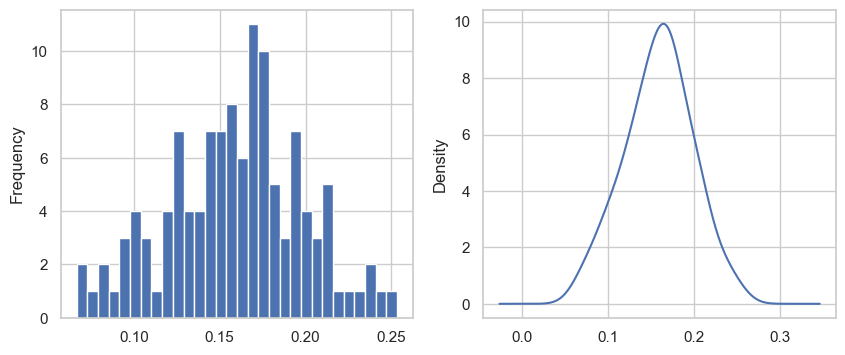

In [37]:
fig_h, axes_h = plt.subplots(1, 2, figsize=(10, 4))
clean["tip_pct"].plot.hist(bins=30, ax=axes_h[0])
clean["tip_pct"].plot.density(ax=axes_h[1])

In [38]:
check("3.6", lambda: len(axes_h[0].patches) == 30 and sum(p.get_height() for p in axes_h[0].patches) == len(clean)
      and len(axes_h[1].lines) == 1)

Task 3.6: PASS


---
# Part 4. Plotting with seaborn (15 points)

seaborn works on top of matplotlib and understands DataFrames: you give `data=...` and column **names**.

| Goal | Code |
|---|---|
| bars with mean and error bar, split by a category | `sns.barplot(data=df, x=..., y=..., hue=...)` |
| scatter with a fitted regression line | `sns.regplot(data=df, x=..., y=...)` |
| box plot per category | `sns.boxplot(data=df, x=..., y=...)` |
| heatmap of a matrix (for example correlations) | `sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)` |

All these functions return the matplotlib `Axes`, so you can continue with `ax.set_title(...)`.
Use `clean` from Part 3. If `import seaborn` failed in the setup cell, run `pip install seaborn` and restart the kernel.

### Theory: seaborn

* seaborn draws **statistical** plots straight from a DataFrame: you pass `data=df` and **column names** as strings.
* **`hue`** splits the data by a category (one colour per category, a legend appears).
* `barplot` shows the **mean** of `y` per `x` with an error bar (95 percent confidence interval); `boxplot` shows median, quartiles, whiskers and outliers;
  `regplot` shows a scatter plus a fitted line with a confidence band; `heatmap` shows a matrix as colours (`annot=True` writes the numbers).
* Each function returns an `Axes`: you can call `ax.set_title(...)` afterwards. `order=[...]` fixes the order of categories.
* Correlation `r` is between -1 and 1: near 1 the variables grow together, near -1 one grows while the other falls, near 0 no linear relation.
  It does not prove that one variable *causes* the other.

### Example (run it and change something)

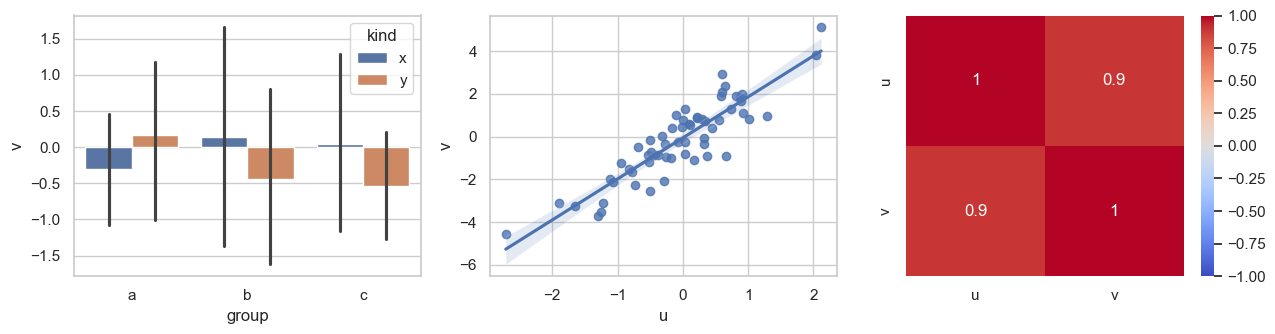

In [39]:
ex_rng = np.random.default_rng(1)
ex_data = pd.DataFrame({"group": np.repeat(["a", "b", "c"], 20), "kind": np.tile(["x", "y"], 30),
                        "u": ex_rng.normal(size=60)})
ex_data["v"] = 2 * ex_data["u"] + ex_rng.normal(size=60)
ex_fig, ex_axes = plt.subplots(1, 3, figsize=(13, 3.5))
sns.barplot(data=ex_data, x="group", y="v", hue="kind", ax=ex_axes[0])      # ax= draws into your own axes
sns.regplot(data=ex_data, x="u", y="v", ax=ex_axes[1])
sns.heatmap(ex_data[["u", "v"]].corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1, ax=ex_axes[2])
ex_fig.tight_layout()

### Task 4.1 (4 pts): barplot with hue

`ax_sns`: a bar plot of the mean `tip_pct` (y) for each `day` (x) split by `time` (`hue`). Use the order
`["Thur", "Fri", "Sat", "Sun"]` for the days.

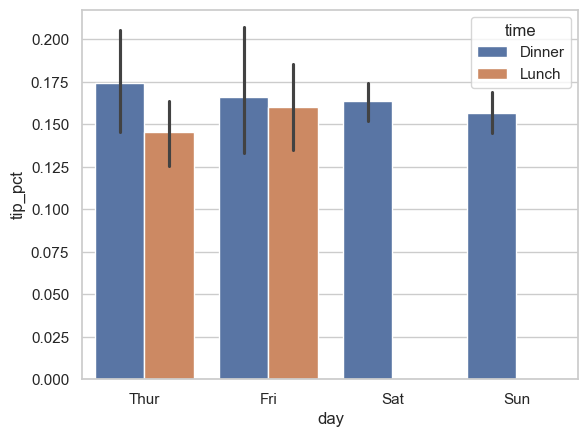

In [40]:
ax_sns = sns.barplot(data=clean, x="day", y="tip_pct", hue="time", order=["Thur", "Fri", "Sat", "Sun"])

In [41]:
check("4.1", lambda: ax_sns.get_xlabel() == "day" and ax_sns.get_ylabel() == "tip_pct"
      and [t.get_text() for t in ax_sns.get_xticklabels()] == ["Thur", "Fri", "Sat", "Sun"]
      and ax_sns.get_legend().get_title().get_text() == "time")

Task 4.1: PASS


### Task 4.2 (4 pts): regplot

`ax_reg`: a regression plot of `tip` (y) against `total_bill` (x), then set its title to `"Tip versus bill"`.

Text(0.5, 1.0, 'Tip versus bill')

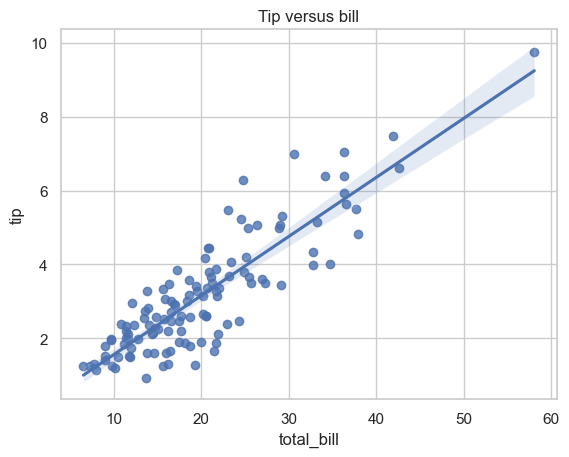

In [42]:
ax_reg = sns.regplot(data=clean, x="total_bill", y="tip")
ax_reg.set_title("Tip versus bill")

In [43]:
check("4.2", lambda: ax_reg.get_title() == "Tip versus bill" and ax_reg.get_xlabel() == "total_bill"
      and len(ax_reg.lines) == 1 and len(ax_reg.collections[0].get_offsets()) == len(clean))

Task 4.2: PASS


### Task 4.3 (3 pts): boxplot

`ax_box`: a **horizontal** box plot of `tip_pct` (x) by `day` (y) with the order `["Thur", "Fri", "Sat", "Sun"]`.

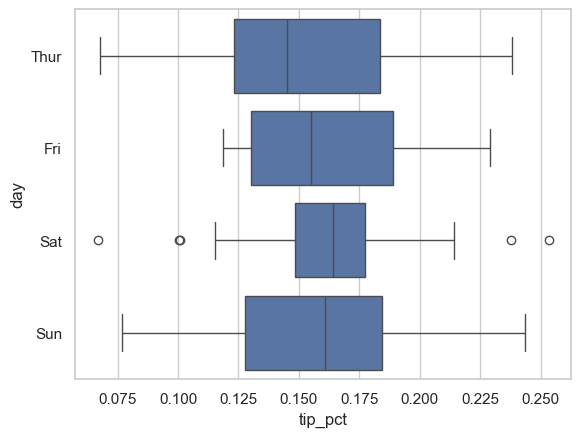

In [44]:
ax_box = sns.boxplot(data=clean, x="tip_pct", y="day", order=["Thur", "Fri", "Sat", "Sun"])

In [45]:
check("4.3", lambda: ax_box.get_xlabel() == "tip_pct" and ax_box.get_ylabel() == "day"
      and [t.get_text() for t in ax_box.get_yticklabels()] == ["Thur", "Fri", "Sat", "Sun"] and len(ax_box.lines) > 0)

Task 4.3: PASS


### Task 4.4 (4 pts): Heatmap of correlations

1. `corr`: the correlation matrix of the columns `["total_bill", "tip", "size", "tip_pct"]` of `clean` (`.corr()`).
2. `ax_heat`: a heatmap of `corr` with the numbers written in the cells (`annot=True`), `cmap="coolwarm"`,
   and the colour scale fixed from `-1` to `1` (`vmin`, `vmax`).

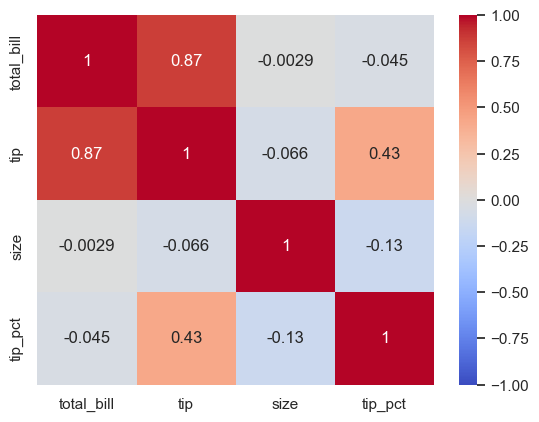

In [46]:
corr = clean[["total_bill", "tip", "size", "tip_pct"]].corr()
ax_heat = sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)

In [47]:
def _t44():
    cols = ["total_bill", "tip", "size", "tip_pct"]
    return (corr.shape == (4, 4) and np.allclose(corr.to_numpy(), clean[cols].corr().to_numpy())
            and len(ax_heat.texts) == 16 and ax_heat.collections[0].get_clim() == (-1.0, 1.0)
            and [t.get_text() for t in ax_heat.get_xticklabels()] == cols)
check("4.4", _t44)

Task 4.4: PASS


---
# Part 5. Mini project: dashboard on regions of Kazakhstan (19 points)

Build **one figure with four panels** about the population of Kazakhstan. Data: `kz` (area, population in 2009 and 2022).
Only rows with `kind == "region"` are used: the cities of national status (Almaty, Astana, Shymkent) and Baikonur are excluded.

| Position | Panel |
|---|---|
| top left | horizontal bar chart: population 2022 of the **5 largest** regions |
| top right | pie chart: share of those 5 regions and of everybody else (`Other`) |
| bottom left | scatter: area (x) against population 2022 (y), the most populated region is annotated |
| bottom right | horizontal bar chart: population growth 2009 to 2022 in percent, for all regions |

### Theory: a dashboard and the "top N + Other" pattern

* A **dashboard** is one figure with several panels that answer one business question. Build it with `fig, axes = plt.subplots(2, 2, figsize=(...))`,
  draw into `axes[i, j]` (pandas: `ax=axes[i, j]`), give **every panel its own title and axis names**, then
  `fig.suptitle("...")`, `fig.tight_layout()` and `fig.savefig(...)`.
* A **pie chart** shows parts of **one whole**: `s.plot.pie(autopct="%1.1f%%", startangle=90)`. With many categories the small slices become unreadable,
  so keep the **top N** (`s.nlargest(N)`) and merge the rest into one slice `Other`.
  When you need to compare many categories precisely, use a bar chart instead.
* Growth in percent: `(new / old - 1) * 100`.

### Example: top N + Other (run it and change N)

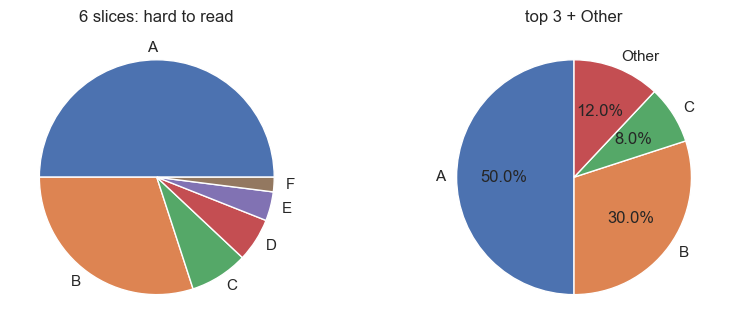

In [48]:
ex_pop = pd.Series({"A": 50, "B": 30, "C": 8, "D": 6, "E": 4, "F": 2})
ex_top = ex_pop.nlargest(3)
ex_share = pd.concat([ex_top, pd.Series({"Other": ex_pop.sum() - ex_top.sum()})])      # top 3 + one slice for the rest
ex_fig, ex_axes = plt.subplots(1, 2, figsize=(9, 3.5))
ex_pop.plot.pie(ax=ex_axes[0], title="6 slices: hard to read")
ex_share.plot.pie(ax=ex_axes[1], autopct="%1.1f%%", startangle=90, title="top 3 + Other")
ex_fig.tight_layout()

### Task 5.1 (3 pts): Prepare the data

1. `regions`: a copy of `kz` with only `kind == "region"` rows, plus a new column `growth_pct` = `(pop_2022 / pop_2009 - 1) * 100`.
2. `top5`: a Series with the `pop_2022` of the **5 most populated** regions, index = region name (`nlargest`, `set_index`).
3. `share`: `top5` plus one more element `"Other"` = population of all the other regions (`pd.concat` with a one-element Series).

In [49]:
regions = kz.loc[kz["kind"] == "region"].copy()
regions["growth_pct"] = (regions["pop_2022"] / regions["pop_2009"] - 1) * 100
top5 = regions.set_index("region")["pop_2022"].nlargest(5)
share = pd.concat([top5, pd.Series({"Other": regions["pop_2022"].sum() - top5.sum()})])

In [50]:
def _t51():
    exp_top = regions.sort_values("pop_2022", ascending=False).head(5)
    return (len(regions) == 17 and set(regions["kind"]) == {"region"}
            and np.allclose(regions["growth_pct"], (regions["pop_2022"] / regions["pop_2009"] - 1) * 100)
            and list(top5.index) == list(exp_top["region"]) and len(share) == 6 and share.index[-1] == "Other"
            and share.sum() == regions["pop_2022"].sum())
check("5.1", _t51)

Task 5.1: PASS


### Task 5.2 (4 pts): Figure, bar panel and pie panel

1. `dash, dax = ...`: a 2 by 2 figure of size `(12, 9)`.
2. **Top left**: horizontal bar chart of `top5` **sorted ascending** (`sort_values()`), so that the largest bar is on top:
   `top5.sort_values().plot.barh(ax=...)`.
3. **Top right**: pie chart of `share` with percentages (`autopct="%1.1f%%"`) and `startangle=90`:
   `share.plot.pie(ax=..., ...)`.

<Axes: >

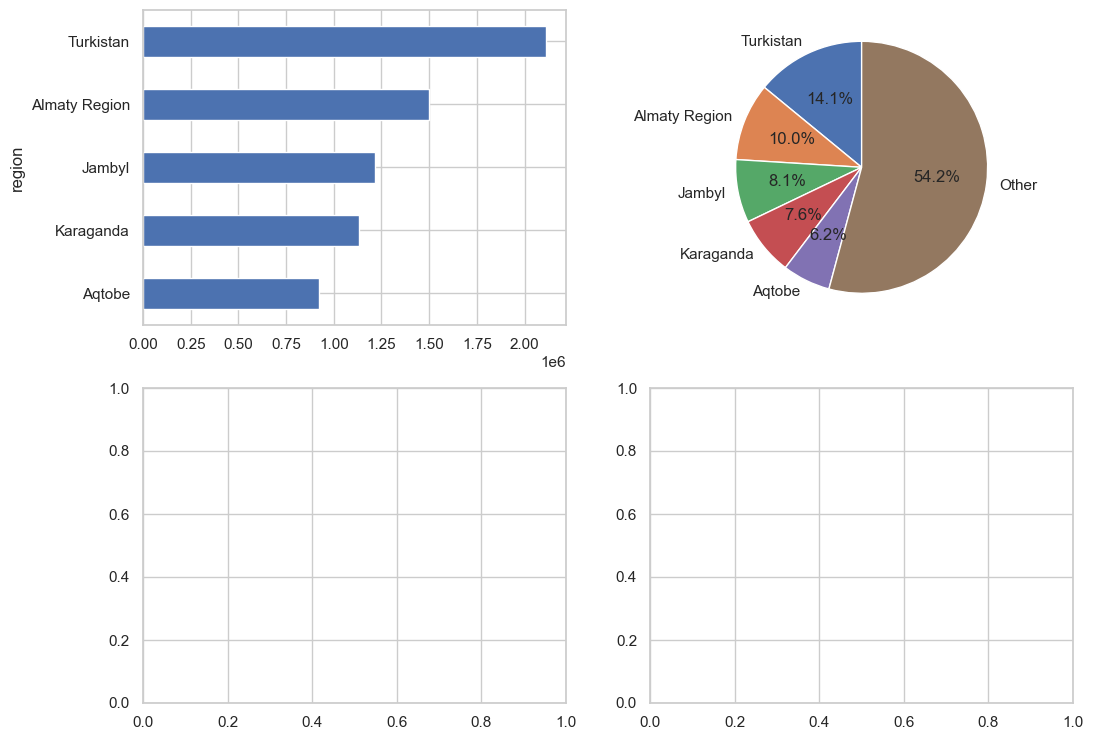

In [51]:
dash, dax = plt.subplots(2, 2, figsize=(12, 9))
top5.sort_values().plot.barh(ax=dax[0, 0])
share.plot.pie(ax=dax[0, 1], autopct="%1.1f%%", startangle=90)

In [52]:
def _t52():
    bars = [p.get_width() for p in dax[0, 0].patches]
    return (len(dash.axes) == 4 and tuple(dash.get_size_inches()) == (12.0, 9.0)
            and len(bars) == 5 and bars == sorted(bars) and np.allclose(sorted(bars), sorted(top5.to_numpy()))
            and len(dax[0, 1].patches) == 6 and any("%" in t.get_text() for t in dax[0, 1].texts))
check("5.2", _t52)

Task 5.2: PASS


### Task 5.3 (3 pts): Scatter with an annotation

**Bottom left**: scatter of `area_km2` (x) against `pop_2022` (y) for `regions`. Then annotate the **most populated region**:
the text is its name, `xy` is its point, move the text away (`xytext` with `textcoords="offset points"`) and draw an arrow
(`arrowprops=dict(arrowstyle="->")`).

*Hint:* `regions.loc[regions["pop_2022"].idxmax()]` gives the row.

In [53]:
dax[1, 0].scatter(regions["area_km2"], regions["pop_2022"])
big = regions.loc[regions["pop_2022"].idxmax()]
dax[1, 0].annotate(big["region"], xy=(big["area_km2"], big["pop_2022"]), xytext=(20, 20), textcoords="offset points", arrowprops=dict(arrowstyle="->"))

Text(20, 20, 'Turkistan')

Task 5.3: PASS


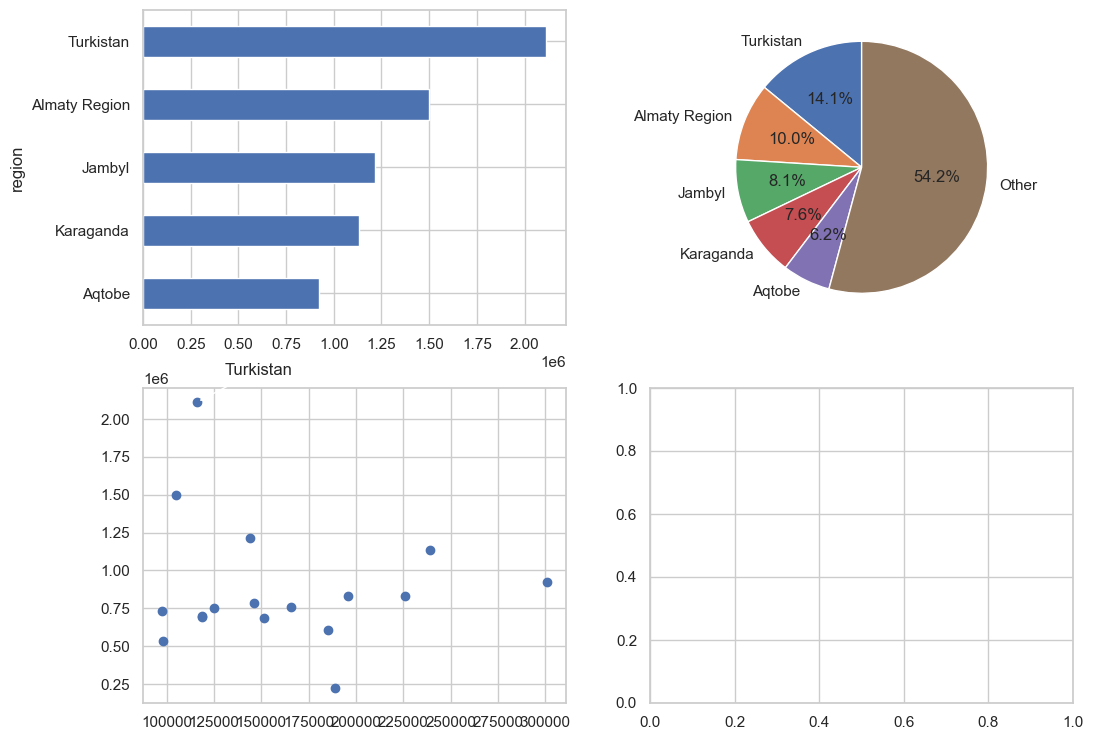

In [54]:
def _t53():
    ax = dax[1, 0]
    anns = [t for t in ax.texts if isinstance(t, Annotation)]
    big = regions.loc[regions["pop_2022"].idxmax()]
    return (len(ax.collections) == 1 and len(ax.collections[0].get_offsets()) == len(regions)
            and len(anns) == 1 and anns[0].get_text() == big["region"]
            and np.allclose(anns[0].xy, (big["area_km2"], big["pop_2022"])) and anns[0].arrow_patch is not None)
check("5.3", _t53)
dash

### Task 5.4 (3 pts): Growth panel

**Bottom right**: horizontal bar chart of `growth_pct` for all regions, **sorted ascending**, with the region names as labels
(`regions.set_index("region")["growth_pct"]` ...).

In [55]:
regions.set_index("region")["growth_pct"].sort_values().plot.barh(ax=dax[1, 1])

<Axes: ylabel='region'>

Task 5.4: PASS


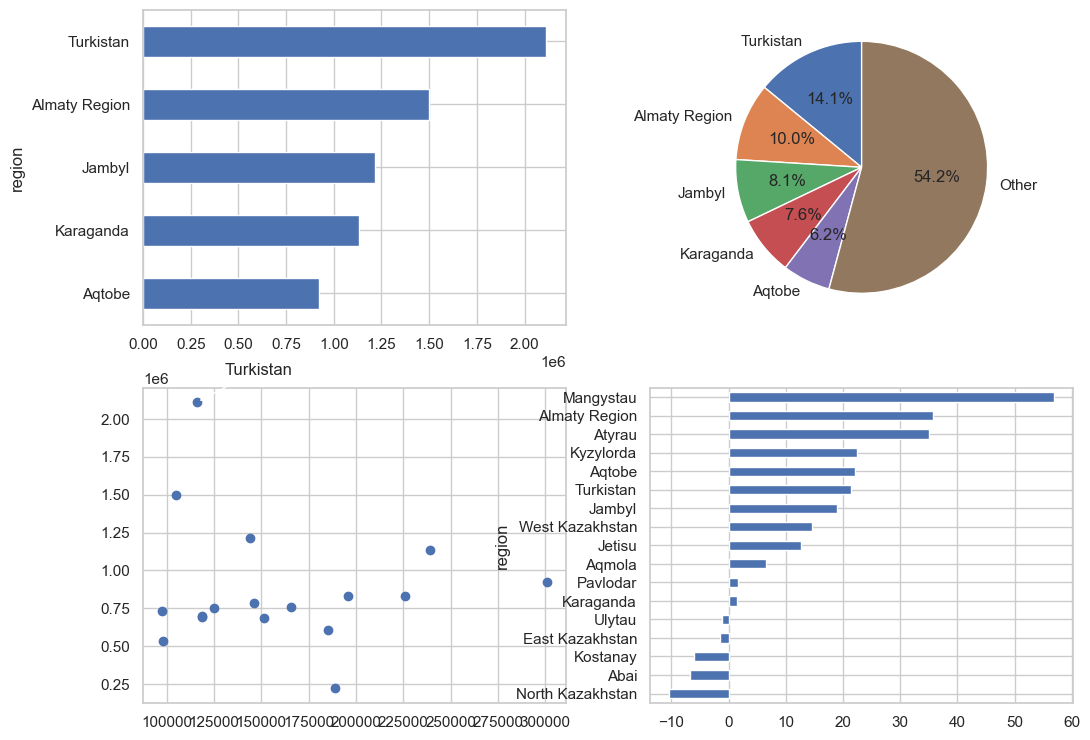

In [56]:
def _t54():
    ax = dax[1, 1]
    bars = [p.get_width() for p in ax.patches]
    return (len(bars) == 17 and np.allclose(bars, sorted(regions["growth_pct"])) and bars[0] < 0
            and sorted(t.get_text() for t in ax.get_yticklabels()) == sorted(regions["region"]))
check("5.4", _t54)
dash

### Task 5.5 (3 pts): Titles and axis names

Give **every one of the four axes** its own (different) title. The three non-pie panels also need an x label and a y label
(the pie does not need axis names).

*Hint:* `ax.set(title=..., xlabel=..., ylabel=...)`. For example the growth panel: x label `"Growth 2009 to 2022, %"`.

In [57]:
dax[0, 0].set(title="Top 5 regions by population", xlabel="Population in 2022", ylabel="Region")
dax[0, 1].set_title("Population share")
dax[1, 0].set(title="Area versus population", xlabel="Area (km²)", ylabel="Population in 2022")
dax[1, 1].set(title="Population growth by region", xlabel="Growth 2009 to 2022, %", ylabel="Region")

[Text(0.5, 1.0, 'Population growth by region'),
 Text(0.5, 4.4444444444444375, 'Growth 2009 to 2022, %'),
 Text(510.27272727272714, 0.5, 'Region')]

Task 5.5: PASS


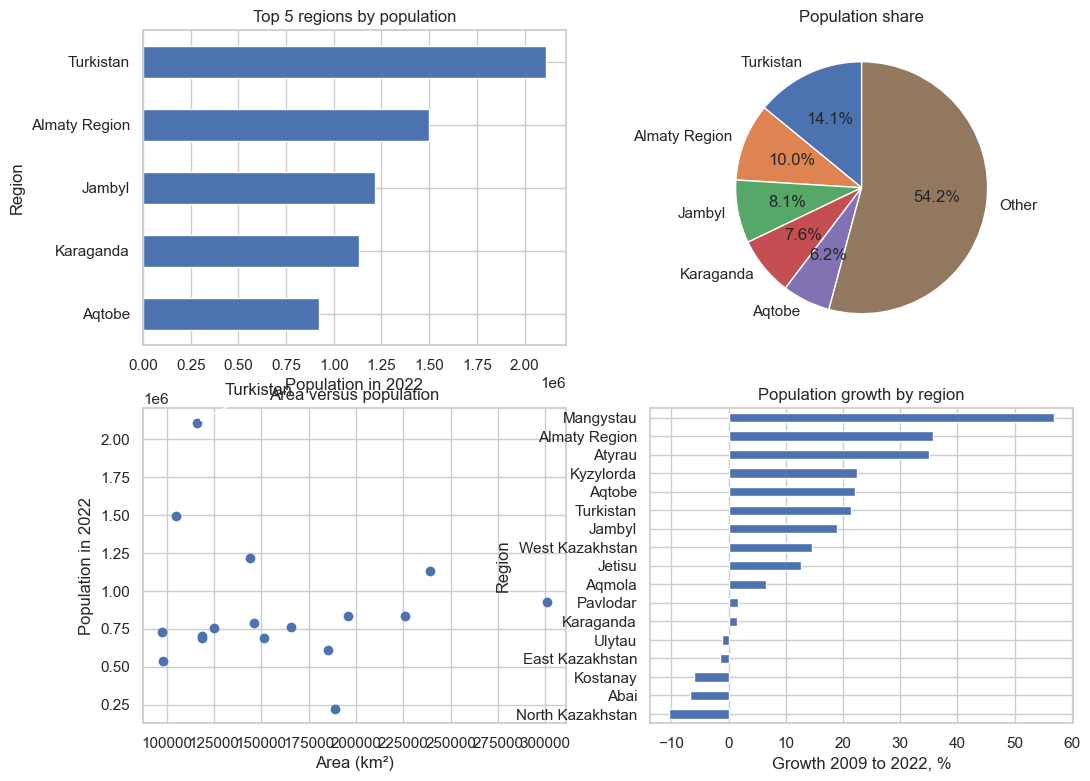

In [58]:
def _t55():
    titles = [a.get_title() for a in dax.ravel()]
    others = [dax[0, 0], dax[1, 0], dax[1, 1]]
    return (all(titles) and len(set(titles)) == 4 and all(a.get_xlabel() for a in others) and all(a.get_ylabel() for a in others))
check("5.5", _t55)
dash

### Task 5.6 (3 pts): Figure title and saving

1. Give the whole figure the title `"Kazakhstan regions dashboard"` with `dash.suptitle(...)`.
2. Call `dash.tight_layout()` so that the panels do not overlap.
3. Save `dash` to `kz_dashboard.png` with `dpi=150`.

In [59]:
dash.suptitle("Kazakhstan regions dashboard")
dash.tight_layout()
dash.savefig("kz_dashboard.png", dpi=150)

Task 5.6: PASS


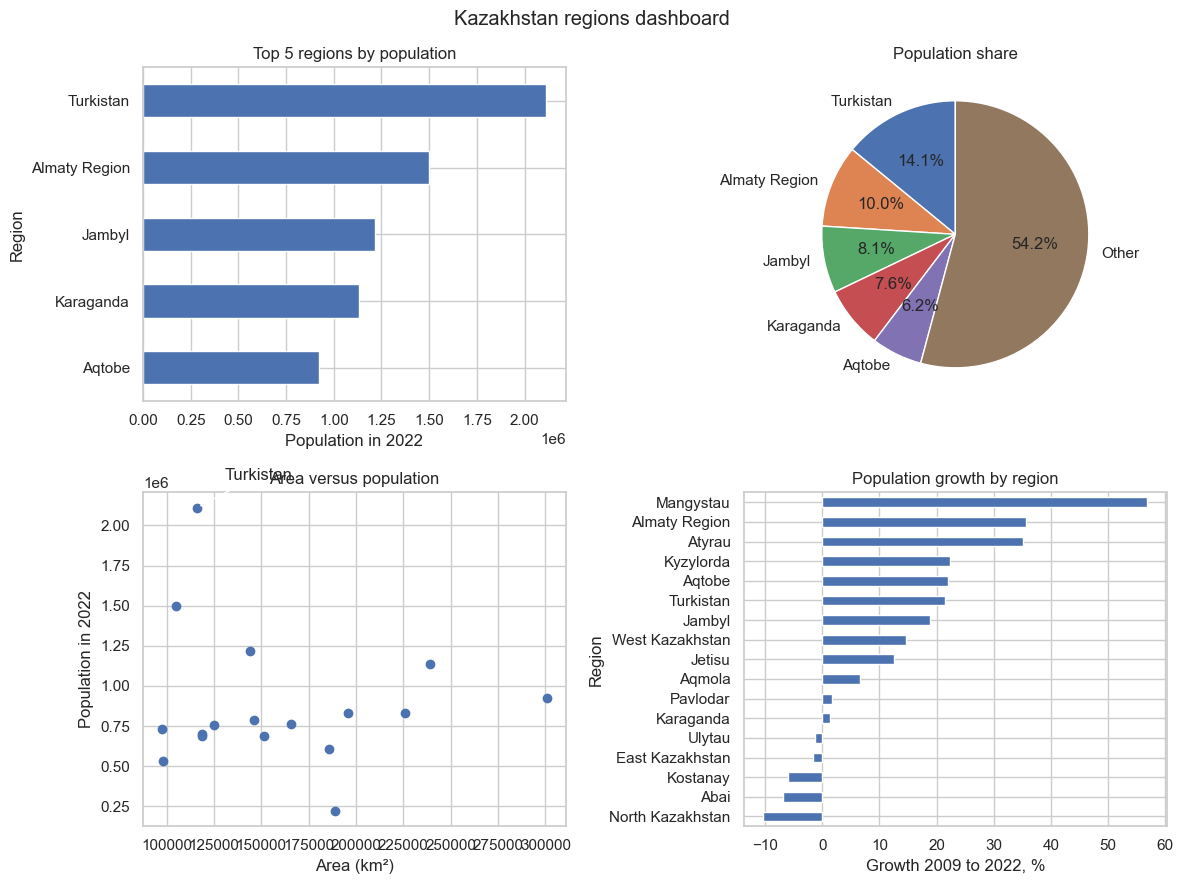

In [60]:
def _suptitle(f):   # get_suptitle() exists only in matplotlib 3.8+, the private attribute works everywhere
    st = getattr(f, "_suptitle", None)
    return st.get_text() if st is not None else ""

check("5.6", lambda: _suptitle(dash) == "Kazakhstan regions dashboard" and os.path.exists("kz_dashboard.png")
      and _png_width("kz_dashboard.png")[0] and _png_width("kz_dashboard.png")[1] >= 1700)   # 12 inches * 150 dpi = 1800
dash

---
# Final score
Run the next cell.

In [61]:
summary()

,max,earned,result
task,,,
1.1,4,4,PASS
1.2,5,5,PASS
1.3,5,5,PASS
1.4,4,4,PASS
1.5,4,4,PASS
2.1,5,5,PASS
2.2,5,5,PASS
2.3,5,5,PASS
2.4,5,5,PASS



Part 1:  22 / 22
Part 2:  20 / 20
Part 3:  24 / 24
Part 4:  15 / 15
Part 5:  19 / 19
TOTAL (automatic): 100 / 100


---
# Defense questions

1. What is a `Figure` and what is an `Axes`? What is the difference between `plt.plot(...)` and `ax.plot(...)`?
2. What does the format string `"ko--"` mean? How would you write the same with keyword arguments?
3. What does `sharex=True` do? What do `wspace` and `hspace` control?
4. Why must you call `set_xticks` before `set_xticklabels`?
5. Why did we remove the row with `tip_pct` at least 1 before plotting? What would the histogram look like without that step?
6. What is the difference between a grouped and a stacked bar chart? Why did we divide each row of the crosstab by its total in task 3.5?
7. **Live demo:** in task 3.6 plot `tips` instead of `clean`. What happens to the histogram and why?
8. In Part 5, why did we group the small regions into `Other` before drawing the pie? When is a bar chart better than a pie?
9. In the heatmap (task 4.4): why are all diagonal values equal to 1? Does a high correlation mean that one variable causes the other?